# 03 · Train a liver fat model (template)

A starter for the trained per-panel models: predict **fatty liver** from the Liver panel plus age
and sex, labelled by elastography CAP (≥ 285 dB/m, a common NHANES cut-off for steatosis). The
label comes from imaging, not from the inputs, so the model can't just restate a lab cut-off.

It follows the contract in `backend/analysis.py`: the model sees the panel's `inputs` in their
fixed order (canonical units, missing as NaN) plus age and sex. Reports often lack some liver
tests, so training randomly hides values to match.

This is a template: the exported model is written to `ml/artifacts/` (git-ignored) and isn't
loaded by the backend yet. `04_evaluate_liver_model.ipynb` tests it in depth. Run
`01_nhanes_dataset.ipynb` first.

In [1]:
import sys
from pathlib import Path

ML_DIR = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ML_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nhanes  # also puts backend/ on the path
from biomarkers import PANELS

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
DATA = ML_DIR / "data"


In [2]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import train_test_split

adults = pd.read_parquet(DATA / "nhanes_2017_2020_adults.parquet")
panel = PANELS["liver"]
FEATURES = [n for n in panel["inputs"] if n in adults.columns]
print("Liver panel inputs available in NHANES:", FEATURES)
print("Not available:", [n for n in panel["inputs"] if n not in adults.columns])

data = adults[adults["elastography_complete"] & adults["cap_dbm"].notna()].copy()
data["fatty_liver"] = (data["cap_dbm"] >= 285).astype(int)
data["male"] = (data["sex"] == "male").astype(int)
X_COLS = FEATURES + ["age", "male"]
print(f"{len(data):,} adults with a complete elastography exam; "
      f"{np.average(data['fatty_liver'], weights=data['weight']):.1%} have CAP ≥ 285 (weighted)")

Liver panel inputs available in NHANES: ['Bilirubin, Total', 'Alkaline Phosphatase', 'AST', 'ALT', 'GGT', 'Albumin', 'Total Protein', 'Globulin', 'Albumin/Globulin Ratio']
Not available: ['Bilirubin, Direct', 'Bilirubin, Indirect']
7,767 adults with a complete elastography exam; 35.8% have CAP ≥ 285 (weighted)


In [3]:
train, test = train_test_split(data, test_size=0.25, random_state=0, stratify=data["fatty_liver"])


def hide_values(frame, rate=0.25, seed=0):
    """Randomly blank lab values (not age/sex), like reports that skip some liver tests."""
    out = frame.copy()
    mask = np.random.default_rng(seed).random((len(out), len(FEATURES))) < rate
    out[FEATURES] = out[FEATURES].mask(mask)
    return out


train_aug = pd.concat([train, hide_values(train, seed=1)])
model = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0, random_state=0)
model.fit(train_aug[X_COLS], train_aug["fatty_liver"], sample_weight=train_aug["weight"])

# Baseline: ALT alone, the liver test people most often look at.
alt_ok = train["ALT"].notna()
baseline = LogisticRegression().fit(np.log(train.loc[alt_ok, ["ALT"]]), train.loc[alt_ok, "fatty_liver"],
                                    sample_weight=train.loc[alt_ok, "weight"])

In [4]:
def evaluate(frame, label):
    p = model.predict_proba(frame[X_COLS])[:, 1]
    y, w = frame["fatty_liver"], frame["weight"]
    return {"set": label, "adults": len(frame), "AUROC": roc_auc_score(y, p, sample_weight=w),
            "Brier": brier_score_loss(y, p, sample_weight=w)}


alt_test = test[test["ALT"].notna()]
baseline_auc = roc_auc_score(alt_test["fatty_liver"], baseline.predict_proba(np.log(alt_test[["ALT"]]))[:, 1],
                             sample_weight=alt_test["weight"])
results = pd.DataFrame([evaluate(test, "test, all values"), evaluate(hide_values(test, seed=2), "test, 25% of labs hidden")])
print(f"Baseline (ALT only) test AUROC: {baseline_auc:.3f}")
results.set_index("set").style.format({"AUROC": "{:.3f}", "Brier": "{:.3f}"})

Baseline (ALT only) test AUROC: 0.686


,adults,AUROC,Brier
set,,,
"test, all values",1942,0.732,0.195
"test, 25% of labs hidden",1942,0.720,0.199


## Calibration and subgroups

A risk shown to a patient has to mean what it says, and work comparably across groups.

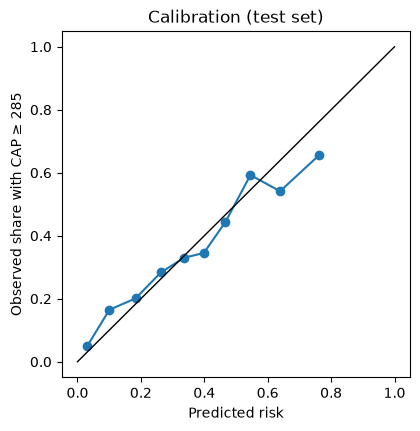

,adults,AUROC
group,,
sex = female,984,0.727
sex = male,958,0.731
race_ethnicity = Mexican American,229,0.737
race_ethnicity = Non-Hispanic Asian,236,0.789
race_ethnicity = Non-Hispanic Black,536,0.723
race_ethnicity = Non-Hispanic White,640,0.728
race_ethnicity = Other Hispanic,204,0.709


In [5]:
from sklearn.calibration import calibration_curve

p_test = model.predict_proba(test[X_COLS])[:, 1]
frac, mean_pred = calibration_curve(test["fatty_liver"], p_test, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(mean_pred, frac, marker="o")
ax.plot([0, 1], [0, 1], color="black", linewidth=1)
ax.set(xlabel="Predicted risk", ylabel="Observed share with CAP ≥ 285", title="Calibration (test set)")
plt.show()

groups = []
for column in ["sex", "race_ethnicity"]:
    for value, g in test.assign(p=p_test).groupby(column):
        if g["fatty_liver"].nunique() == 2 and len(g) >= 100:
            groups.append({"group": f"{column} = {value}", "adults": len(g),
                           "AUROC": roc_auc_score(g["fatty_liver"], g["p"], sample_weight=g["weight"])})
pd.DataFrame(groups).set_index("group").style.format({"AUROC": "{:.3f}"})

## Export

Saved with the metadata the backend will need to load it safely: the exact input order and the
panel's `schema_version` (the loader should refuse a model whose version doesn't match).

In [6]:
import json
import joblib
from sklearn import __version__ as sklearn_version

out_dir = ML_DIR / "artifacts" / "liver_fatty_liver" / "v1"
out_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(model, out_dir / "model.joblib")
metadata = {
    "panel": "liver",
    "schema_version": panel["schema_version"],
    "features": X_COLS,
    "label": "Elastography CAP >= 285 dB/m (NHANES 2017-March 2020)",
    "training_rows": int(len(train)),
    "metrics": {row["set"]: {"AUROC": round(row["AUROC"], 3), "Brier": round(row["Brier"], 3)} for row in results.to_dict("records")},
    "baseline_alt_auroc": round(baseline_auc, 3),
    "sklearn_version": sklearn_version,
}
(out_dir / "metadata.json").write_text(json.dumps(metadata, indent=2))
print(json.dumps(metadata, indent=2))

{
  "panel": "liver",
  "schema_version": 1,
  "features": [
    "Bilirubin, Total",
    "Alkaline Phosphatase",
    "AST",
    "ALT",
    "GGT",
    "Albumin",
    "Total Protein",
    "Globulin",
    "Albumin/Globulin Ratio",
    "age",
    "male"
  ],
  "label": "Elastography CAP >= 285 dB/m (NHANES 2017-March 2020)",
  "training_rows": 5825,
  "metrics": {
    "test, all values": {
      "AUROC": 0.732,
      "Brier": 0.195
    },
    "test, 25% of labs hidden": {
      "AUROC": 0.72,
      "Brier": 0.199
    }
  },
  "baseline_alt_auroc": 0.686,
  "sklearn_version": "1.9.1"
}


**Before this model goes in the app:** compare against the published Fatty Liver Index /
Hepatic Steatosis Index (they use BMI, which reports don't have), check performance on the
2021–2023 cycle as an external test, and decide how to present the risk on the Liver card.